# Market Risk Statistical Validation Framework
### A classical-statistics analysis of return distributions, systematic risk, market stress, and Value-at-Risk model calibration

**Scope:** statistical analysis and validation of market-risk measures using classical statistical methods
(probability distributions, hypothesis testing, classical linear regression, and VaR backtesting).

**Out of scope (deliberately):** machine learning, advanced derivatives pricing, stochastic volatility models
(GARCH), copulas, Monte Carlo simulation, and regulatory capital modelling. Every technique used below is
closed-form / classical inference — there is no fitted ML model anywhere in this notebook.

**Structure**

1. Data & Log Returns
2. Distribution Analysis — Normal vs Student-t
3. Low vs High Volatility Regimes — Hypothesis Testing
4. Market Model Regression — Systematic Risk (Beta) across 4 stocks
5. Stress-Day Flagging — Type I / Type II Error Analysis
6. Value at Risk — Historical & Parametric
7. VaR Backtesting — Kupiec Proportion-of-Failures Test
8. Conclusions


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy.stats as stats

import risk_utils as ru

plt.rcParams["figure.figsize"] = (9, 4.5)
pd.set_option("display.float_format", lambda x: f"{x:,.5f}")

def format_pvalue(p):
    if pd.isna(p):
        return "N/A"
    if p == 0:
        return "<1e-300"
    if p < 0.0001:
        return f"{p:.2e}"
    return f"{p:.4f}"


## Configuration

Market index: **NIFTY 50** (`^NSEI`).
Stocks: four large-caps from different sectors — `RELIANCE.NS`, `TCS.NS`, `HDFCBANK.NS`, `INFY.NS`
(energy/conglomerate, IT, private banking, IT — enough sector spread to make the beta comparison meaningful).

> Requires internet access to fetch data via `yfinance`. Adjust `START` / `END` as needed.

In [2]:
MARKET_TICKER = "^NSEI"
STOCK_TICKERS = ["RELIANCE.NS", "TCS.NS", "HDFCBANK.NS", "INFY.NS"]
START, END = "2019-01-01", "2024-12-31"

all_tickers = [MARKET_TICKER] + STOCK_TICKERS
prices = ru.download_prices(all_tickers, START, END)
prices = prices.rename(columns={MARKET_TICKER: "NIFTY50"})
prices.tail()


Ticker,HDFCBANK.NS,INFY.NS,RELIANCE.NS,TCS.NS,NIFTY50
Date,,,,,
2024-12-23,874.03430,"1,829.40137","1,211.83472","3,872.73755","23,753.44922"
2024-12-24,872.62683,"1,814.90344","1,212.28076","3,892.48193","23,727.65039"
2024-12-26,869.05988,"1,813.33484","1,206.13391","3,882.79614","23,750.19922"
2024-12-27,872.69965,"1,822.22375","1,210.59546","3,878.83813","23,813.40039"
2024-12-30,862.82373,"1,812.00391","1,200.33398","3,873.20312","23,644.90039"


## 1. Data & Log Returns

$$R_t = \ln\left(\frac{P_t}{P_{t-1}}\right)$$

Log returns are used throughout (time-additive, closer to symmetric than simple returns — the standard
convention in market-risk work).

In [3]:
returns = ru.log_returns(prices)
returns.tail()


Ticker,HDFCBANK.NS,INFY.NS,RELIANCE.NS,TCS.NS,NIFTY50
Date,,,,,
2024-12-23,0.01652,0.00112,0.01401,-0.00288,0.00701
2024-12-24,-0.00161,-0.00796,0.00037,0.00509,-0.00109
2024-12-26,-0.00410,-0.00086,-0.00508,-0.00249,0.00095
2024-12-27,0.00418,0.00489,0.00369,-0.00102,0.00266
2024-12-30,-0.01138,-0.00562,-0.00851,-0.00145,-0.00710


In [4]:
stats_table = returns.apply(ru.descriptive_stats).T
stats_table


,mean_daily,std_daily,annualised_vol,skewness,excess_kurtosis
Ticker,,,,,
HDFCBANK.NS,0.00035,0.01652,0.26231,-0.36129,9.45724
INFY.NS,0.00080,0.01765,0.28023,-0.78767,12.15833
RELIANCE.NS,0.00059,0.01843,0.29253,0.11755,9.86301
TCS.NS,0.00059,0.01524,0.24198,-0.12683,4.61782
NIFTY50,0.00051,0.01166,0.18509,-1.58831,21.87987


### Observations

* NIFTY 50 has the lowest annualised volatility (18.51%), while RELIANCE has the highest (29.25%) among the four stocks. This indicates that individual stocks exhibit greater return variability than the diversified market index during the sample period.
* All four stocks show positive average daily returns, although the magnitudes are small.
* INFY (-0.788) and NIFTY 50 (-1.588) exhibit noticeable negative skewness, indicating greater asymmetry toward large negative returns. HDFCBANK also shows mild negative skewness (-0.361), while RELIANCE is approximately symmetric (0.118).
* Excess kurtosis is substantially greater than zero for every series, ranging from 4.62 for TCS to 21.88 for NIFTY 50. This indicates heavy-tailed return distributions with more extreme observations than expected under a Normal distribution.
* The combination of negative skewness and high excess kurtosis suggests that downside and tail risk are important characteristics of these equity returns.

### Conclusion

The descriptive statistics show that the return series are not well characterised by a simple Normal distribution, particularly in the tails. Although NIFTY 50 has lower overall volatility than the individual stocks, its strong negative skewness and very high excess kurtosis indicate significant tail behaviour. These findings provide statistical motivation for the next stage of the framework: comparing Normal and Student-t distributions to assess which distribution better captures the observed return characteristics and their implications for market-risk measurement.


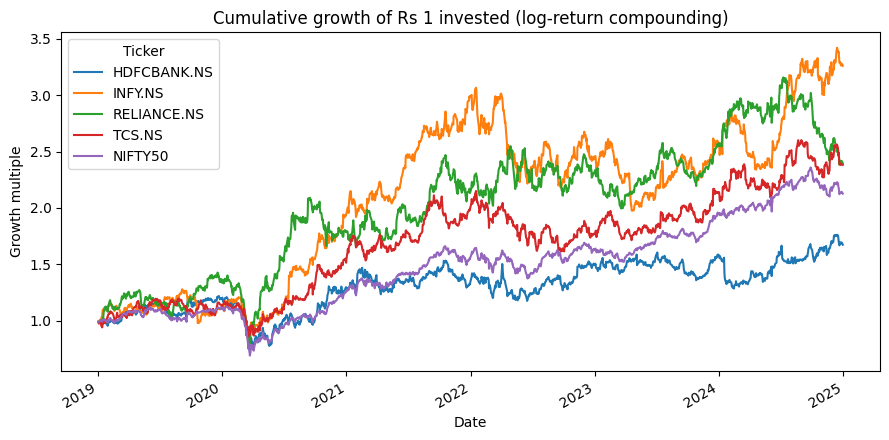

In [5]:
fig, ax = plt.subplots()
np.exp(returns.cumsum()).plot(ax=ax)
ax.set_title("Cumulative growth of Rs 1 invested (log-return compounding)")
ax.set_ylabel("Growth multiple")
plt.tight_layout()
plt.show()

### Observations

* The cumulative-growth plot shows how ₹1 invested in each asset at the beginning of the sample would have evolved through compounded log returns.
* INFY achieves the highest cumulative growth by the end of the sample, at approximately ₹3.3, followed by RELIANCE and TCS at around ₹2.4, while NIFTY 50 reaches approximately ₹2.2 and HDFCBANK approximately ₹1.7.
* All assets experience a sharp decline around early 2020, clearly reflecting a major market-stress episode, followed by different recovery paths.
* The stocks show substantial differences in realised performance over the sample period, with INFY significantly outperforming the market index in cumulative terms.
* Importantly, **return performance ≠ risk characteristics**. INFY's strong cumulative growth does not imply that it was the least risky asset; its earlier statistics show relatively high volatility, negative skewness, and substantial excess kurtosis.
* Therefore, an asset with higher realised returns can simultaneously exhibit greater volatility and more severe tail behaviour, demonstrating why return performance must be analysed separately from risk characteristics.

### Conclusion

The cumulative-growth analysis demonstrates that the selected assets produced markedly different investment outcomes over 2019–2024, but cumulative return alone does not provide a complete assessment of investment quality. The contrast between INFY's strong growth and its substantial volatility and tail risk highlights the central principle that **return performance ≠ risk characteristics**. This motivates the broader framework: market performance must be evaluated together with distributional behaviour, stress sensitivity, systematic risk, and downside-risk measures such as VaR. Thus, the purpose of the project is not simply to identify the best-performing asset, but to statistically understand and validate the risk associated with market returns.


## 2. Distribution Analysis — Normal vs Student-t

**Question: are financial returns actually normally distributed?**

This matters directly for risk management: parametric VaR (Section 6) assumes normality. If returns are
fat-tailed, a normal-distribution VaR model will *understate* the probability of extreme losses.

A Normal-parametric VaR model assumes returns follow a Normal distribution; parametric VaR itself can be built using other distributions, such as Student-t.

In [6]:
market_returns = returns["NIFTY50"]

normal_params = ru.fit_normal(market_returns)
t_params = ru.fit_student_t(market_returns)
jb_result = ru.goodness_of_fit_normal(market_returns)

print("Normal fit:", normal_params)
print("Student-t fit:", t_params, "  <- low df = fatter tails than normal")

print("\nJarque-Bera normality test")
print(f"  Statistic : {jb_result['jarque_bera_stat']:.4f}")
print(f"  p-value   : {format_pvalue(jb_result['p_value'])}")
print(f"  Reject H0 : {jb_result['reject_normality_at_5pct']}")

Normal fit: {'loc': np.float64(0.000512126255157476), 'scale': np.float64(0.011655480155777533)}
Student-t fit: {'df': np.float64(3.1514170248349678), 'loc': np.float64(0.0009589007617830125), 'scale': np.float64(0.006919161092155353)}   <- low df = fatter tails than normal

Jarque-Bera normality test
  Statistic : 30021.6783
  p-value   : <1e-300
  Reject H0 : True


### Observations

* The fitted Normal model has mean approximately (0.000512) and daily standard deviation (0.011655), while the fitted Student-t model estimates approximately (3.15) degrees of freedom. Such a low degrees-of-freedom parameter indicates substantially heavier tails than the Normal distribution.
* The Student-t fit is consistent with the earlier descriptive statistics, where NIFTY 50 exhibited strong negative skewness ((-1.588)) and extremely high excess kurtosis ((21.88)). Thus, the evidence for non-Normality is not based on a single statistic; both the shape diagnostics and fitted distribution point toward significant tail behaviour.
* The Jarque-Bera statistic is extremely large ((30,021.68)) with a p-value below (10^{-300}), providing overwhelming statistical evidence against the null hypothesis of Normality.
* The result demonstrates an important risk-modelling principle: **a distribution can have moderate overall volatility while still having severe tail risk**. NIFTY 50's annualised volatility is only about 18.5%, yet its extreme kurtosis shows that unusually large returns occur much more frequently than a Normal model would imply.
* This means that measuring risk using volatility alone can miss an important part of market risk. The critical issue is not only how much returns fluctuate on average, but also **how frequently and how severely the distribution produces extreme observations**.
* The analysis also shows why distribution choice matters for VaR: if a Normal model assigns too little probability to the far-left tail, a Normal-parametric VaR can produce a deceptively precise-looking risk threshold while understating the likelihood of extreme losses.

### Conclusion

The Normality assumption is decisively rejected for NIFTY 50 returns over the 2019–2024 sample. The combination of strong negative skewness, very high excess kurtosis, an extremely significant Jarque-Bera test, and a Student-t fit with only about 3.15 degrees of freedom provides consistent evidence of **heavy-tailed and asymmetric market returns**. Therefore, the key conclusion is:

[
\boxed{\text{Normal-looking volatility does not imply Normal tail risk}}
]

More importantly for the framework, **distributional assumptions are themselves a source of model risk**. A risk model based on an inappropriate thin-tailed Normal assumption may underestimate extreme-loss probability, which is why the subsequent VaR analysis must examine how different distributional assumptions translate into actual risk estimates and whether those estimates survive backtesting.


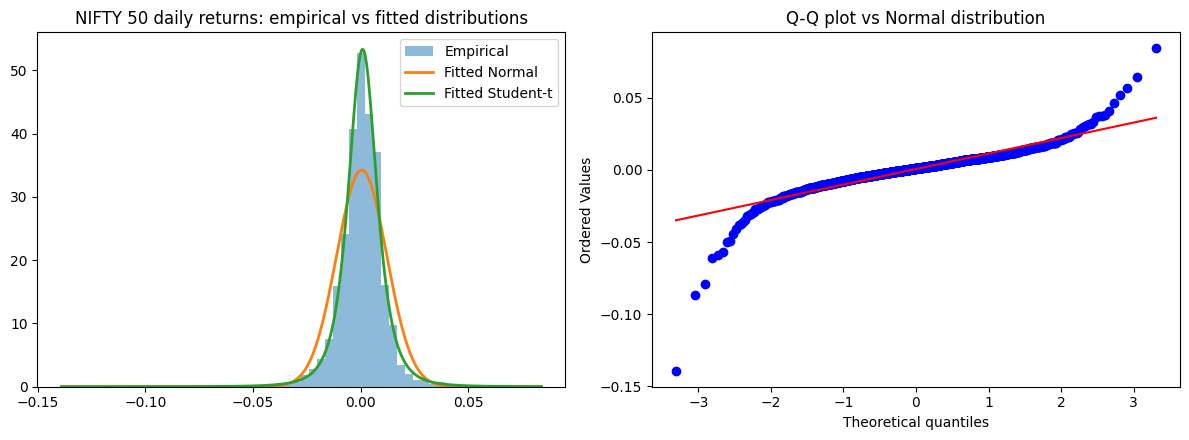

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

# Histogram vs fitted densities
x = np.linspace(market_returns.min(), market_returns.max(), 500)
axes[0].hist(market_returns, bins=60, density=True, alpha=0.5, label="Empirical")
axes[0].plot(x, stats.norm.pdf(x, **normal_params), label="Fitted Normal", lw=2)
axes[0].plot(x, stats.t.pdf(x, **t_params), label="Fitted Student-t", lw=2)
axes[0].set_title("NIFTY 50 daily returns: empirical vs fitted distributions")
axes[0].legend()

# Q-Q plot against Normal
stats.probplot(market_returns, dist="norm", plot=axes[1])
axes[1].set_title("Q-Q plot vs Normal distribution")

plt.tight_layout()
plt.show()


What happens to risk measurement if I use the wrong distribution?

### Observations

* The empirical NIFTY 50 return distribution exhibits substantially heavier tails than the fitted Normal distribution. The Normal curve captures the central mass reasonably well but becomes increasingly inadequate in the extreme regions of the return distribution.
* The fitted Student-t distribution provides a more plausible representation of the observed tail behaviour because its finite degrees of freedom ((\nu \approx 3.15)) allow substantially more probability mass in the extremes than the Normal distribution.
* The Q-Q plot provides strong visual evidence against Normality: observations in both tails systematically deviate from the reference line, with particularly large negative observations falling far below the Normal expectation. This indicates that extreme market losses occur more frequently and/or are more severe than a Normal model would predict.
* The important distinction is that the Normal model is not necessarily poor across the entire distribution; its major weakness appears in the **tails**, which are precisely the region most relevant to downside-risk measurement and VaR.
* The visual evidence is consistent with the earlier statistical results: NIFTY 50 has strongly negative skewness ((-1.588)), very high excess kurtosis ((21.88)), and a Jarque-Bera p-value below (10^{-300}). Therefore, the evidence for non-Normality is consistent across descriptive statistics, formal testing, fitted distributions, and graphical diagnostics.
* This demonstrates an important model-risk principle: **a model can appear reasonable around average market behaviour while still being seriously wrong in the tail.** For risk management, getting the centre of the distribution approximately right is not enough if the model systematically understates extreme-loss probability.
* Consequently, distribution selection can materially affect VaR estimates. A Normal-parametric VaR may assign insufficient probability to extreme losses, whereas a heavy-tailed specification such as Student-t can produce a more conservative representation of tail risk.

### Conclusion

The empirical distribution and Q-Q diagnostics reinforce the statistical rejection of Normality and show that NIFTY 50 returns contain substantial heavy-tail and asymmetric behaviour. The central portion of the distribution may appear broadly compatible with a bell-shaped model, but the extreme observations clearly depart from Normal expectations. Therefore:

[
\boxed{\text{Good fit in the centre} \neq \text{Good fit for tail risk}}
]

This is the key reason distribution choice matters in market-risk modelling. The results provide a direct statistical basis for comparing different VaR methodologies in the later sections and testing whether a Normal-parametric VaR adequately captures actual market-loss frequency.

### Interpretation: 
points curving away from the reference line in the Q-Q plot tails — and a
significant Jarque-Bera p-value — indicate the normal distribution understates the frequency of extreme
returns. The Student-t fit (finite degrees of freedom) captures this fat-tail behaviour much better. This
directly motivates comparing Historical vs Parametric-Normal VaR in Section 6.


## 3. Low vs High Volatility Regimes — Hypothesis Testing

**Question: are returns during high-volatility periods statistically different from low-volatility periods?**

"High-volatility" is defined structurally here via *trailing realised volatility*
(21-day rolling standard deviation, split at the sample median). This is a slower,
regime-level classification based on the recent volatility environment rather than
any single day's return.

The median split is **not intended to claim that 50% of trading days were crisis or
financially stressed days**. Instead, it creates two balanced empirical regimes:
the lower-volatility half and the higher-volatility half of the observed volatility
distribution.

This regime classification is reused in Section 5 as the reference ("ground truth")
for evaluating a separate, faster daily stress-flagging rule.

Because Section 2 showed that returns are **not normally distributed**, the
non-parametric Mann-Whitney U test is the primary test here; Welch's t-test is
reported alongside it as a complementary mean-based comparison that does not
assume equal variances.

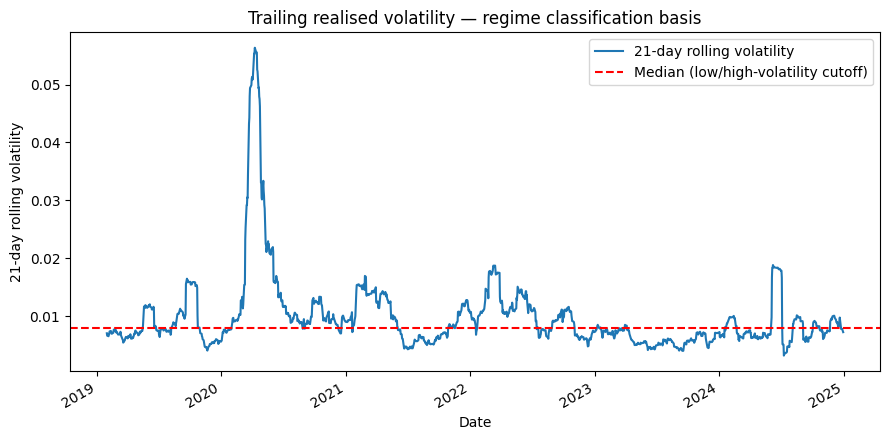

low_vol     727
high_vol    727
Name: count, dtype: int64

In [8]:
regime, rolling_vol = ru.classify_regime(
    market_returns,
    window=21,
    method="median"
)

fig, ax = plt.subplots()

rolling_vol.plot(
    ax=ax,
    label="21-day rolling volatility"
)

ax.axhline(
    rolling_vol.median(),
    color="red",
    ls="--",
    label="Median (low/high-volatility cutoff)"
)

ax.set_title("Trailing realised volatility — regime classification basis")
ax.set_ylabel("21-day rolling volatility")
ax.legend()

plt.tight_layout()
plt.show()

regime.value_counts()

### Observations

* The 21-day trailing volatility series demonstrates that **market risk is strongly time-varying**. NIFTY 50 moves through prolonged periods of relatively low volatility as well as distinct episodes of elevated volatility rather than maintaining one constant risk level.
* The most pronounced volatility expansion occurs around early 2020, where rolling volatility rises dramatically above the median cutoff. This provides a clear example of a transition into a high-volatility market environment following a major shock.
* Elevated volatility also appears in later clusters, particularly around 2021–2022 and 2024, showing that high-risk conditions are **episodic and recurrent**, rather than being associated with only one historical event.
* The median cutoff is approximately (0.008), so observations above this level are classified as `high_vol`, while those at or below it are classified as `low_vol`. The classification therefore measures **relative volatility state within the sample**, not an absolute declaration of financial crisis.
* The classification produces exactly 727 `low_vol` and 727 `high_vol` observations. This 50/50 split is a consequence of using the sample median and is desirable here because the purpose of Section 3 is to create two sufficiently large, balanced empirical groups for statistical comparison.
* Therefore, **“high-volatility” should not be interpreted as “50% of days were financially stressed.”** It means that the market was operating above its own historical median volatility during those observations. This is a relative regime label, not a crisis-frequency estimate.
* The rolling measure is deliberately slower than a daily shock indicator. A single extreme return may temporarily increase rolling volatility, but the regime depends on the accumulated behaviour of the recent 21-day window. Thus:

[
\boxed{\text{Extreme return} \neq \text{high-volatility regime}}
]

* Conversely, a day with a moderate return can still belong to the `high_vol` regime if the preceding weeks have been characterized by persistently elevated volatility. This distinction separates **point-in-time shock risk** from **state-dependent market risk**.
* The high-volatility regime therefore provides a useful reference state for the next stage of the framework: testing whether return behaviour changes across volatility environments and later evaluating whether a faster daily stress rule can identify the high-risk regime.
* The design also avoids circularity in the later stress-detection analysis. The reference regime is determined from a **slow, historical volatility measure**, while the later daily flag is a separate fast indicator whose accuracy can be evaluated using Type I and Type II errors.

### Conclusion

The 21-day rolling-volatility analysis establishes that NIFTY 50 experiences **distinct and persistent volatility states**, with major expansions in risk around identifiable market-stress episodes. The median split does not claim that half of the observations are crisis days; rather, it creates a balanced empirical distinction between relatively low- and high-volatility environments.

The central risk-management insight is:

[
\boxed{\text{Market risk is state-dependent, not constant}}
]

and:

[
\boxed{\text{An extreme daily shock is different from a persistent high-volatility regime}}
]

Using `low_vol` and `high_vol` therefore gives the framework a more precise interpretation: Section 3 studies whether return behaviour changes across **volatility regimes**, while the later stress-flagging section can separately ask whether a fast daily indicator is capable of detecting those elevated-risk states.


In [9]:
regime_result = ru.compare_regimes(market_returns, regime)
regime_result


{'n_low_vol': 727,
 'n_high_vol': 727,
 'mean_low_vol': np.float64(0.0004996459392605397),
 'mean_high_vol': np.float64(0.0005567456356047257),
 't_test_stat': np.float64(-0.09287262924679339),
 't_test_p': np.float64(0.9260236587145709),
 'mannwhitney_stat': np.float64(251853.0),
 'mannwhitney_p': np.float64(0.1210560445562096),
 'levene_stat': np.float64(116.66400282270864),
 'levene_p': np.float64(3.270176069611894e-26),
 'mean_diff': np.float64(-5.7099696344186e-05),
 'mean_diff_95ci': (np.float64(-0.001263603691109593),
  np.float64(0.001149404298421221))}

### Observations

* The low- and high-volatility regimes contain an equal number of observations (727 each), providing balanced samples for statistical comparison.
* The average daily return is (0.04996%) in the low-volatility regime and (0.05567%) in the high-volatility regime. Although the high-volatility regime has a slightly higher sample mean, the difference is extremely small.
* Welch's t-test produces (t=-0.0929) with (p=0.9260). Therefore, there is no statistically significant evidence that the mean return differs between low- and high-volatility regimes.
* The Mann-Whitney U test, used as the primary non-parametric comparison because the return distribution is non-Normal, gives (p=0.1211). This also fails to reject the null at the 5% significance level, indicating no sufficient evidence of a systematic location/rank difference between the two return samples.
* The 95% confidence interval for the difference in mean returns is approximately ((-0.1264%,,0.1149%)), which contains zero. Thus, a zero difference in average return is entirely consistent with the observed data.
* In contrast, Levene's test gives (p=3.27\times10^{-26}), providing overwhelming evidence that the variances of the two regimes are different.
* This produces an important risk-management result: **the high-volatility regime is not statistically characterised by a different average return, but it is statistically characterised by a different level of dispersion.**
* Therefore, high market risk should not be interpreted simply as "the market is falling." A high-volatility environment can contain both large positive and large negative returns while producing an average return close to that of a low-volatility environment.
* The findings reinforce the distinction between **return direction and return risk**:

[
\boxed{\text{High volatility} \neq \text{lower average return}}
]

but:

[
\boxed{\text{High volatility} \Rightarrow \text{different dispersion of returns}}
]

* This also validates the purpose of the regime construction: the classification is detecting a materially different **risk environment**, rather than merely separating periods with different average market performance.

### Conclusion

The statistical comparison shows that low- and high-volatility regimes do not exhibit a statistically significant difference in average daily returns, but they exhibit an extremely significant difference in variance. Therefore, the defining characteristic of the high-volatility regime in this sample is **greater uncertainty and dispersion, not necessarily negative expected return**.

The key conclusion is:

[
\boxed{\text{Market stress changes the scale of risk more clearly than the direction of return}}
]

This is an important distinction for market-risk modelling. Risk cannot be inferred from average return alone: two periods can have similar average returns while having dramatically different probabilities and magnitudes of extreme outcomes. The result therefore strengthens the motivation for subsequent tail-risk analysis, stress-day detection, and VaR modelling.


## 4. Market Model Regression — Systematic Risk (Beta)

$$R_{i,t} = \alpha + \beta \, R_{m,t} + \epsilon_t$$

This is a **classical OLS regression** (closed-form estimator, full inferential output: standard errors,
p-values, 95% confidence intervals) — **not** an ML regression model. It is deliberately called a *market
model*, not CAPM, because no risk-free rate / excess-return adjustment is applied here.

- **β (beta):** sensitivity of the stock's return to the market's return — systematic risk.
- **α (alpha):** average return not explained by the market — near zero is expected under market efficiency.
- **R²:** proportion of the stock's return variance explained by the market alone (the rest is idiosyncratic).

**Standard errors are HC1 (heteroskedasticity-robust / White), not classical OLS SEs.** Daily equity
returns exhibit volatility clustering — periods of calm and turbulence — so the constant-variance assumption
behind classical OLS standard errors doesn't hold well here. Classical SEs would tend to understate the true
uncertainty around beta, making it look more significant than it is. Robust SEs correct for this without
changing the point estimates of alpha/beta themselves.

In [10]:
reg_rows = []
for ticker in STOCK_TICKERS:
    res = ru.market_model_regression(returns[ticker], market_returns)
    reg_rows.append({
        "stock": ticker,
        "alpha": res["alpha"], "alpha_p": res["alpha_p"],
        "beta": res["beta"], "beta_se": res["beta_se"], "beta_p": res["beta_p"],
        "beta_ci_low": res["beta_ci95"][0], "beta_ci_high": res["beta_ci95"][1],
        "r_squared": res["r_squared"], "n_obs": res["n_obs"],
    })

regression_table = pd.DataFrame(reg_rows).set_index("stock")
regression_table


,alpha,alpha_p,beta,beta_se,beta_p,beta_ci_low,beta_ci_high,r_squared,n_obs
stock,,,,,,,,,
RELIANCE.NS,0.00003,0.92442,1.09272,0.04842,0.00000,0.99782,1.18761,0.47801,1474
TCS.NS,0.00023,0.49941,0.70675,0.04807,0.00000,0.61253,0.80097,0.29224,1474
HDFCBANK.NS,-0.00020,0.47137,1.07646,0.04185,0.00000,0.99445,1.15848,0.57691,1474
INFY.NS,0.00037,0.33062,0.83892,0.04568,0.00000,0.74938,0.92845,0.30703,1474


### Observations

* All four stocks exhibit statistically significant systematic exposure to NIFTY 50. The Beta p-values are effectively zero for every stock, providing strong evidence that broad market movements are associated with stock-level return movements.
* Beta differs substantially across the four stocks. RELIANCE has the highest estimated Beta ((1.093)), followed closely by HDFCBANK ((1.076)), while INFY ((0.839)) and TCS ((0.707)) have materially lower systematic market sensitivity.
* The Beta confidence intervals reinforce these differences. RELIANCE and HDFCBANK have intervals centred around 1, whereas the entire confidence intervals for INFY and TCS lie below 1. Thus, the lower market sensitivity of INFY and TCS is not merely a point-estimate difference; it is supported by statistical uncertainty intervals.
* The results demonstrate that **overall volatility and systematic market exposure are different dimensions of risk**. INFY has relatively high annualised volatility ((28.02%)) but a Beta below 1 ((0.839)), showing that substantial volatility can exist without equally high sensitivity to the broad market.
* TCS provides another useful example: it has the lowest annualised volatility ((24.20%)) and the lowest Beta ((0.707)), indicating both lower overall dispersion and lower sensitivity to NIFTY movements in this sample.
* (R^2) varies considerably across the stocks. HDFCBANK has the highest (R^2) ((57.69%)), followed by RELIANCE ((47.80%)), while INFY ((30.70%)) and TCS ((29.22%)) have much lower values.
* This means that Beta alone does not describe how much of a stock's total return variation is market-driven. HDFCBANK's return variation is more strongly aligned with NIFTY in this one-factor model, whereas a larger proportion of INFY and TCS movements remains unexplained by the market factor.
* None of the four estimated alphas is statistically significant at the 5% level. Therefore, although some estimated intercepts are positive or negative, there is insufficient evidence that the average market-model intercept differs from zero.
* The use of HC1 heteroskedasticity-robust standard errors is important because the earlier regime analysis already demonstrated strong evidence of changing variance across market environments. The robust inference therefore addresses a realistic characteristic of financial returns without changing the OLS point estimates of Alpha and Beta.
* The most important distinction from this analysis is:

[
\boxed{\text{Volatility} \neq \text{Beta} \neq R^2}
]

Volatility measures overall return dispersion, Beta measures sensitivity to the systematic market factor, and (R^2) measures how much of the return variation is explained by that factor.

### Conclusion

The market-model regression demonstrates that the four stocks have significantly different systematic-risk profiles despite being exposed to the same NIFTY 50 market factor. RELIANCE and HDFCBANK exhibit Beta values above 1, while INFY and TCS exhibit lower market sensitivity. However, the differences in (R^2) show that market exposure does not explain the same proportion of total return variation for every stock.

The deeper risk-management conclusion is:

[
\boxed{\text{High volatility does not necessarily mean high Beta}}
]

and:

[
\boxed{\text{Beta does not represent total risk}}
]

A stock may be volatile because of factors that are not captured by the broad market index. Therefore, systematic market exposure must be analysed alongside total volatility and idiosyncratic variation rather than being treated as a complete measure of risk. The regression therefore adds a distinct dimension to the framework: it separates **how much an asset moves** from **how much of that movement is systematically related to the market**.


In [11]:
regression_display = regression_table.copy()

# Regular numerical columns
for col in ["alpha", "beta", "beta_se",
            "beta_ci_low", "beta_ci_high", "r_squared"]:
    regression_display[col] = regression_display[col].map(
        lambda x: f"{x:.4f}"
    )

# p-values
for col in ["alpha_p", "beta_p"]:
    regression_display[col] = regression_display[col].map(format_pvalue)

regression_display

,alpha,alpha_p,beta,beta_se,beta_p,beta_ci_low,beta_ci_high,r_squared,n_obs
stock,,,,,,,,,
RELIANCE.NS,0.0000,0.9244,1.0927,0.0484,8.79e-113,0.9978,1.1876,0.4780,1474
TCS.NS,0.0002,0.4994,0.7067,0.0481,6.29e-49,0.6125,0.8010,0.2922,1474
HDFCBANK.NS,-0.0002,0.4714,1.0765,0.0418,6.21e-146,0.9944,1.1585,0.5769,1474
INFY.NS,0.0004,0.3306,0.8389,0.0457,2.55e-75,0.7494,0.9285,0.3070,1474


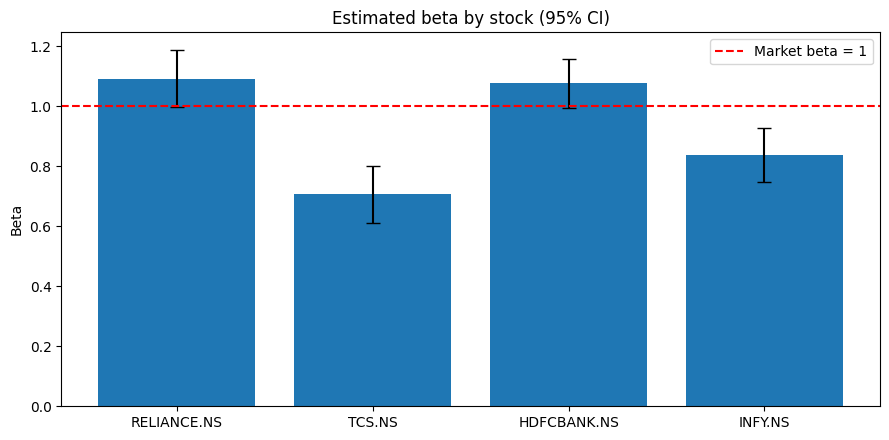

In [12]:
fig, ax = plt.subplots()
ax.bar(regression_table.index, regression_table["beta"],
       yerr=1.96 * regression_table["beta_se"], capsize=5)
ax.axhline(1.0, color="red", ls="--", label="Market beta = 1")
ax.set_title("Estimated beta by stock (95% CI)")
ax.set_ylabel("Beta")
ax.legend()
plt.tight_layout()
plt.show()


### Observations

* The Beta chart shows clear differences in systematic market exposure across the four stocks. RELIANCE ((\beta=1.093)) and HDFCBANK ((\beta=1.076)) have estimated Betas slightly above the market benchmark of 1, while INFY ((\beta=0.839)) and TCS ((\beta=0.707)) have lower market sensitivity.
* The confidence intervals provide important information beyond the point estimates. The 95% interval for TCS ((0.613,,0.801)) and INFY ((0.749,,0.928)) lies entirely below (\beta=1), providing strong evidence that their systematic market sensitivity is below the benchmark.
* RELIANCE ((0.998,,1.188)) and HDFCBANK ((0.994,,1.158)) have intervals that essentially touch or cross the market-beta benchmark. Therefore, their point estimates above 1 should not be interpreted as conclusive evidence that their true Beta is strictly greater than 1.
* The chart demonstrates why reporting confidence intervals is more informative than reporting Beta alone. A point estimate describes the estimated exposure, while the confidence interval describes the uncertainty surrounding that exposure.
* The visual ranking of systematic exposure is approximately:

[
\boxed{\text{RELIANCE} > \text{HDFCBANK} > \text{INFY} > \text{TCS}}
]

* The comparison also reinforces the distinction between **systematic exposure and total risk**. A stock can have substantial volatility without having a Beta above 1. INFY, for example, has relatively high overall volatility but a Beta below 1, suggesting that not all of its return variability is explained by broad NIFTY movements.
* Therefore, the graph demonstrates another central principle of the framework:

[
\boxed{\text{Volatility} \neq \text{Beta} \neq \text{Total risk}}
]

### Conclusion

The Beta visualization confirms that the selected stocks have materially different levels of systematic market exposure. RELIANCE and HDFCBANK are closest to market-level sensitivity, while TCS and INFY exhibit clearly lower sensitivity to broad NIFTY movements.

The deeper conclusion is that **systematic exposure must be interpreted together with statistical uncertainty and overall volatility**. A Beta point estimate alone can give a false sense of precision; confidence intervals reveal whether the observed difference from the market benchmark is statistically meaningful.

Thus:

[
\boxed{\text{Systematic market sensitivity is asset-specific and uncertain}}
]

and:

[
\boxed{\text{A lower Beta does not automatically imply lower total risk}}
]

This distinction is essential because the framework is measuring different dimensions of market risk rather than attempting to compress all risk into a single number.


## 5. Stress-Day Flagging — Type I / Type II Error Analysis

**Question: how well can a fast single-day rule identify observations occurring in a high-volatility market regime?**

The fast rule flags a day as **predicted stress** when its return falls below a
specified lower percentile of the historical return distribution. Three thresholds
(10%, 5%, and 1%) are compared to illustrate the trade-off between alert sensitivity
and selectivity.

This rule is deliberately different from the slower structural regime definition
used in Section 3. Section 3 classifies each observation as `low_vol` or `high_vol`
using 21-day trailing realised volatility. That regime serves as the **reference
state** against which the fast daily rule is evaluated.

|                  | Reference: High-vol | Reference: Low-vol |
|------------------|---------------------|--------------------|
| **Flagged**      | TP                  | FP (Type I)        |
| **Not flagged**  | FN (Type II)        | TN                 |

- **Type I error (false alarm):** flagging a low-volatility observation as stress.
- **Type II error (missed event):** failing to flag an observation belonging to the high-volatility regime.

For a risk manager, these errors have different costs. Excessive false alarms can
consume attention, trigger unnecessary defensive action, or contribute to alert
fatigue, while missed high-risk observations can leave elevated market risk
undetected.

A less selective threshold such as 10% flags more observations and is therefore more
sensitive, while a stricter threshold such as 1% produces fewer alerts but can miss
more observations belonging to the high-volatility regime. The threshold therefore
represents a genuine risk-management trade-off rather than a statistical error to
be eliminated.

**Important scope note — this is an in-sample, retrospective comparison, not an
out-of-sample predictive test.** Both the return-percentile threshold and the
low/high-volatility reference regime are constructed using the full sample,
including observations occurring after the day being classified.

The analysis therefore asks:

> *Across the full historical sample, how well does a fast single-day extreme-return
> rule track the slower high-volatility regime?*

It should **not** be interpreted as evidence that the rule would operate successfully
as a live early-warning system. A genuine predictive evaluation would require a
walk-forward, no-look-ahead design.

In [13]:
results = []

for pct in [10, 5, 1]:

    # Fast/reactive single-day rule
    flagged, threshold = ru.flag_stress_days(
        market_returns,
        percentile=pct
    )

    # Slow structural reference regime from Section 3
    # Section 3 now uses: low_vol / high_vol
    actual = (
        regime.reindex(flagged.index) == "high_vol"
    ).fillna(False)

    metrics = ru.confusion_matrix_metrics(
        actual,
        flagged
    )

    metrics["flag_percentile"] = pct
    metrics["return_threshold"] = threshold

    results.append(metrics)

threshold_table = (
    pd.DataFrame(results)
    .set_index("flag_percentile")
)

threshold_table[
    [
        "TP",
        "FP",
        "FN",
        "TN",
        "recall_sensitivity",
        "specificity",
        "type_I_error_rate_FPR",
        "type_II_error_rate_FNR"
    ]
]

,TP,FP,FN,TN,recall_sensitivity,specificity,type_I_error_rate_FPR,type_II_error_rate_FNR
flag_percentile,,,,,,,,
10,106,42,621,705,0.14580,0.94378,0.05622,0.85420
5,68,6,659,741,0.09354,0.99197,0.00803,0.90646
1,15,0,712,747,0.02063,1.00000,0.00000,0.97937


### Observations

* The results show a clear sensitivity–selectivity trade-off as the single-day return threshold becomes more stringent. Moving from the 10th to the 1st percentile sharply reduces the number of false alarms, but simultaneously causes the rule to miss an increasingly large proportion of observations belonging to the high-volatility regime.
* At the 10% threshold, the rule detects 106 high-volatility observations but misses 621, giving a recall of only (14.58%) and a Type II error rate of (85.42%). Although the detector has a relatively low Type I error rate of (5.62%), most high-volatility observations remain undetected.
* At the 5% threshold, false alarms fall dramatically from 42 to only 6, increasing specificity to (99.20%). However, recall falls further to (9.35%), while the Type II error rate increases to (90.65%). The detector becomes much more selective but substantially less capable of identifying the broader high-volatility state.
* At the 1% threshold, the rule produces zero false positives and therefore (100%) specificity in this sample. However, it identifies only 15 of the 727 high-volatility observations, corresponding to a recall of (2.06%) and a Type II error rate of (97.94%).
* The key result is therefore not that one percentile is "best", but that **no single-day extreme-return threshold provides strong detection of the slower high-volatility regime**. Tightening the threshold improves false-alarm control, but the loss of sensitivity becomes extreme.
* This provides empirical evidence for the conceptual distinction introduced earlier:

[
\boxed{\text{Extreme return} \neq \text{high-volatility regime}}
]

A high-volatility market state can contain many ordinary-looking daily returns because the regime is defined by the accumulated variability of recent observations, not by whether today's return is among the most extreme historical losses.

* The large Type II rates are therefore not merely a weakness of threshold selection. They reveal a structural limitation of using **only today's return** to identify a **multi-day volatility state**.
* The results also demonstrate why risk-monitoring systems must consider the cost of both error types. A very selective detector can achieve almost perfect specificity while providing almost no useful coverage of the actual high-volatility regime.
* The analysis should be interpreted as a retrospective comparison rather than evidence that the percentile rule would work as a live warning system, because both the return threshold and the high-volatility reference regime are computed from the full sample.

### Conclusion

The threshold analysis shows that a fast, single-day extreme-return rule is fundamentally different from a structural volatility-regime indicator. Increasing the threshold from 10% to 5% to 1% makes the detector increasingly conservative: false alarms fall from (5.62%) to (0%), but Type II error rises from (85.42%) to (97.94%).

The central conclusion is:

[
\boxed{\text{False-alarm control can be improved by becoming stricter, but detection of the broader risk regime deteriorates sharply}}
]

More importantly:

[
\boxed{\text{A single extreme-return rule is not an adequate proxy for persistent market stress}}
]

The experiment therefore demonstrates why **event detection and regime identification should not be treated as the same problem**. A daily shock rule may be useful for identifying unusually severe individual losses, but it is poorly suited to recognising a sustained high-volatility environment. This distinction motivates the broader framework's use of separate tools for distributional risk, volatility regimes, stress detection, and ultimately VaR model validation.


## 6. Value at Risk — Historical & Parametric

**Historical VaR:** the empirical alpha-quantile of realised returns — no distributional assumption.

**Parametric (Normal) VaR:** $VaR = -(\mu + z_\alpha \sigma)$ — assumes returns are normally distributed.

**On the fat-tail effect from Section 2:** it's tempting to assume fat tails always make the parametric-normal
VaR *understate* risk relative to the historical estimate — but that isn't guaranteed at every confidence
level. Excess kurtosis reshapes the whole distribution (a taller peak, thinner shoulders, and fatter far-tails),
and at a moderate quantile like 95% the empirical value can actually sit *closer to the centre* than the
normal fit predicts, even though the same fat tails would dominate at a more extreme quantile like 99%. So
which estimate is more conservative at 95% is an empirical question, not something to assume in advance —
Section 7b below checks whether the ordering flips at 99%, which is where the fat-tail effect should actually
show up.

**Translating VaR into a loss figure:** a VaR percentage only becomes useful to a risk manager once it's
converted into money. Suppose the desk holds an illustrative Rs 40 crore combined exposure across the four
stocks in this notebook — the cell below converts today's VaR estimate into an estimated one-day loss at
that exposure size.

In [14]:
alpha = 0.05  # 95% VaR
hvar = ru.historical_var(market_returns, alpha)
pvar = ru.parametric_var(market_returns, alpha)

print(f"95% Historical VaR  : {hvar:.4%} (daily)")
print(f"95% Parametric VaR  : {pvar:.4%} (daily)")
print(f"Difference          : {(hvar - pvar):.4%}  "
      f"{'(historical is more conservative)' if hvar > pvar else '(parametric is more conservative)'}")

EXPOSURE = 4e7  # illustrative Rs 4 crore total exposure -- edit to taste
print()
print(f"Illustrative exposure: Rs {EXPOSURE:,.0f}")
print(f"Estimated 1-day 95% loss (Historical) : Rs {ru.var_to_exposure_loss(hvar, EXPOSURE):,.0f}")
print(f"Estimated 1-day 95% loss (Parametric) : Rs {ru.var_to_exposure_loss(pvar, EXPOSURE):,.0f}")


95% Historical VaR  : 1.5477% (daily)
95% Parametric VaR  : 1.8666% (daily)
Difference          : -0.3189%  (parametric is more conservative)

Illustrative exposure: Rs 40,000,000
Estimated 1-day 95% loss (Historical) : Rs 619,077
Estimated 1-day 95% loss (Parametric) : Rs 746,638


### Observations

* At the 95% confidence level, Historical VaR is (1.5477%) of daily portfolio value, while Normal Parametric VaR is (1.8666%). Therefore, the Normal-parametric estimate is more conservative than the empirical Historical estimate by (0.3189%).
* For the illustrative ₹4 crore exposure, this corresponds to an estimated one-day loss threshold of approximately ₹6.19 lakh under Historical VaR and ₹7.47 lakh under Normal Parametric VaR. The distributional assumption therefore changes the monetary risk estimate by roughly ₹1.28 lakh at the same confidence level.
* The result is important because Section 2 established strong evidence of non-Normal, heavy-tailed returns. Nevertheless, the presence of fat tails does **not** guarantee that a Normal VaR will be smaller than Historical VaR at every confidence level.
* At the moderate 95% quantile, the empirical 5th percentile of NIFTY returns happens to be closer to the centre than the fitted Normal lower-tail quantile. Therefore, the Normal model is more conservative at this particular confidence level despite the underlying return distribution being strongly non-Normal.
* This demonstrates that the effect of distributional misspecification depends not only on whether the data are heavy-tailed, but also on **which part of the distribution is being used for the risk calculation**. A model can behave differently at 95% and 99% because the importance of the far tail increases as the confidence level becomes more extreme.
* Historical VaR and Normal Parametric VaR therefore represent two different modelling philosophies. Historical VaR relies directly on realised observations and makes no parametric distributional assumption, while Normal VaR imposes a Normal shape on the return distribution.
* The comparison shows why the statement **“fat tails imply Normal VaR always understates risk”** is too strong. The correct question is empirical: **how does the chosen model behave at the specific confidence level being used?**
* The monetary conversion also highlights why VaR is operationally useful. A statistical percentage threshold becomes meaningful to a risk manager only after it is translated into the potential financial impact on the exposure.

### Conclusion

The 95% VaR analysis demonstrates that distributional assumptions can materially change the estimated downside-loss threshold. For this sample, Normal Parametric VaR is more conservative than Historical VaR at the 95% confidence level, even though the earlier distribution analysis showed substantial non-Normality and fat tails.

The key methodological conclusion is:

[
\boxed{\text{Fat tails do not determine VaR ordering at every confidence level}}
]

Instead:

[
\boxed{\text{VaR behaviour depends on both distributional shape and tail quantile}}
]

Therefore, neither Historical nor Normal Parametric VaR should be declared superior from this comparison alone. The next step is **backtesting**: examine how frequently each VaR threshold is actually violated and test whether that frequency is statistically consistent with the model's stated confidence level.


## 7. Out-of-Sample VaR Backtesting — Kupiec Proportion-of-Failures Test

**Why not just backtest on the same data VaR was estimated from?** Because that has look-ahead bias — a
VaR estimate computed from the full sample already "knows" about every day it's then tested against,
including days that happened years after the estimate would have been made in real life. That doesn't
demonstrate the model works on unseen data; it just checks self-consistency.

**The fix — walk-forward (out-of-sample) backtesting:** for each day *t*, VaR is estimated using only the
trailing `window` days before *t* (default 250 ≈ one trading year). That estimate is then tested only
against day *t* itself, which was never used to compute it. The window slides forward one day at a time and
repeats. This is what `rolling_out_of_sample_var` in `risk_utils.py` implements.

If the model is correctly calibrated at the 95% level, roughly 5% of the out-of-sample days should be
violations. With *T* out-of-sample observations we expect about $0.05 \times T$ violations. The
**Kupiec (1995) POF test** formally checks whether the *observed* violation count is statistically
consistent with that *expected* rate:

$$LR_{POF} = -2\ln\!\left[(1-\alpha)^{T-x}\alpha^{x}\right] + 2\ln\!\left[(1-x/T)^{T-x}(x/T)^{x}\right] \sim \chi^2_{(1)}$$

A significant result (p < 0.05) means the model is mis-calibrated — either too conservative (too few
violations) or too aggressive (too many).

In [15]:
WINDOW = 250  # ~1 trading year of history used to estimate each day's VaR

bt_historical = ru.rolling_out_of_sample_var(market_returns, window=WINDOW, alpha=alpha, method="historical")
bt_parametric = ru.rolling_out_of_sample_var(market_returns, window=WINDOW, alpha=alpha, method="parametric")

print(f"Out-of-sample test period: {len(bt_historical)} days "
      f"({bt_historical.index.min().date()} to {bt_historical.index.max().date()})")
print(f"Historical-VaR violations : {int(bt_historical['violation'].sum())}")
print(f"Parametric-VaR violations : {int(bt_parametric['violation'].sum())}")


Out-of-sample test period: 1224 days (2020-01-16 to 2024-12-30)
Historical-VaR violations : 66
Parametric-VaR violations : 59


### Observations

* The VaR models are evaluated using a **walk-forward out-of-sample procedure**, where each day's VaR estimate is calculated exclusively from the preceding 250 trading days and is then tested against the next unseen return. This removes the look-ahead problem that would arise from estimating VaR once on the full sample and testing it against observations that were already used in estimation.
* The out-of-sample evaluation covers 1,224 trading days from 16 January 2020 to 30 December 2024. At the 95% confidence level, the expected violation probability is (5%), corresponding to approximately (61.2) violations over the test period.
* Historical VaR produces 66 violations, corresponding to an empirical violation rate of approximately (5.39%). This is slightly above the theoretical 5% target but remains close to the expected frequency.
* Normal Parametric VaR produces 59 violations, corresponding to an empirical violation rate of approximately (4.82%). This is slightly below the theoretical 5% target and is also very close to the expected frequency.
* The Kupiec POF statistic is approximately (0.387) for Historical VaR ((p\approx0.534)) and (0.084) for Normal Parametric VaR ((p\approx0.772)). Both p-values are well above 0.05, so there is insufficient evidence to reject the hypothesis that the observed violation probabilities equal the intended 5% rate.
* The result is particularly informative because the two models produced different VaR magnitudes in Section 6, with Normal Parametric VaR being more conservative at the 95% level, yet both models remain statistically consistent with the target exception frequency in the out-of-sample period.
* This demonstrates why **VaR magnitude alone is not enough to judge a risk model**. A model may produce a larger or smaller numerical VaR, but what matters for validation is whether its realised exception frequency is consistent with its stated confidence level.
* The analysis also distinguishes **calibration from proof of correctness**. Failing to reject the Kupiec null does not prove that a model is universally correct; it means that its unconditional violation frequency is statistically compatible with the expected rate.
* Since Kupiec POF examines the frequency of exceptions, it does not by itself test whether violations are clustered in time. Therefore, the current result supports **unconditional coverage**, but does not establish that the model captures the timing or independence structure of violations.

### Conclusion

The walk-forward backtest provides strong evidence that both Historical and Normal Parametric 95% VaR are **unconditionally well calibrated** over the 2020–2024 out-of-sample period. Historical VaR produces slightly more violations than expected, while Normal Parametric VaR produces slightly fewer, but neither deviation is statistically significant under the Kupiec POF test.

The central methodological conclusion is:

[
\boxed{\text{A VaR estimate is not validated by its magnitude; it is validated by how it performs on unseen data}}
]

and:

[
\boxed{\text{Observed violation frequency} \approx \text{Expected violation frequency}}
]

for both models in this sample.

This is the strongest validation step in the framework because it converts the earlier distributional and VaR calculations into an actual empirical model-performance test. It also demonstrates why **out-of-sample, no-look-ahead backtesting is fundamentally more informative than testing a VaR estimate on the same data from which it was derived**.


In [16]:
for label, bt in [("Historical VaR (out-of-sample)", bt_historical),
                   ("Parametric VaR (out-of-sample)", bt_parametric)]:
    x = int(bt["violation"].sum())
    T = len(bt)
    kupiec = ru.kupiec_pof_test(x, T, alpha=alpha)
    print(f"--- {label} ---")
    for k, v in kupiec.items():
        print(f"  {k}: {v}")
    print()


--- Historical VaR (out-of-sample) ---
  observed_violations: 66
  expected_violations: 61.2
  observed_rate: 0.05392156862745098
  expected_rate: 0.05
  LR_stat: 0.3868384931520268
  p_value: 0.533965922899686
  reject_model_at_5pct: False

--- Parametric VaR (out-of-sample) ---
  observed_violations: 59
  expected_violations: 61.2
  observed_rate: 0.04820261437908497
  expected_rate: 0.05
  LR_stat: 0.08420976185436757
  p_value: 0.7716715111651359
  reject_model_at_5pct: False



### Observations

* The walk-forward backtest contains 1,224 genuinely out-of-sample observations. The 95% VaR models therefore imply an expected violation probability of (5%), or approximately (61.2) violations over the test period.
* Historical VaR produces 66 violations, corresponding to an observed exception rate of (5.39%). The difference from the expected 5% rate is small.
* Normal Parametric VaR produces 59 violations, corresponding to an observed exception rate of (4.82%). This is also very close to the 5% target and is slightly more conservative in terms of realised exception frequency.
* The Kupiec POF statistic for Historical VaR is (0.3868) with (p=0.5340), while the Normal Parametric VaR statistic is (0.0842) with (p=0.7717). Both p-values are well above the 5% significance threshold, so the null hypothesis of a 5% violation probability is not rejected for either model.
* The comparison is particularly interesting because Section 2 strongly rejected the Normality assumption. Nevertheless, the Normal-parametric VaR is not rejected by Kupiec at the 95% confidence level. This shows that **distributional non-Normality does not automatically imply unconditional VaR miscalibration at every confidence level**.
* The result demonstrates why risk-model validation should be empirical rather than assumption-driven. A theoretically questionable distributional assumption can still produce a VaR threshold whose observed exception frequency is statistically consistent with its target over a particular sample and confidence level.
* Conversely, passing Kupiec does not prove that the entire VaR model is correct. The test evaluates **unconditional coverage**, meaning whether the overall exception frequency is consistent with the nominal rate. It does not determine whether violations cluster during particular market regimes or whether the model performs equally well during calm and turbulent periods.
* This distinction connects directly to the earlier regime analysis: market volatility was shown to be strongly state-dependent, so a model could have the correct total number of violations while still performing poorly during high-volatility episodes.

### Conclusion

Both Historical and Normal Parametric 95% VaR pass the Kupiec unconditional-coverage test in the walk-forward out-of-sample period. Historical VaR produces a slightly higher-than-target violation rate, while Normal Parametric VaR produces a slightly lower-than-target rate, but neither deviation is statistically significant.

The central model-validation conclusion is:

[
\boxed{\text{Normality rejection does not automatically imply VaR rejection}}
]

and:

[
\boxed{\text{Passing Kupiec means correct exception frequency, not complete model validation}}
]

Therefore, the evidence supports both VaR models as **unconditionally calibrated at the 95% level for this sample**, while leaving open the more demanding question of whether the models behave correctly across different market regimes or at more extreme confidence levels such as 99%.


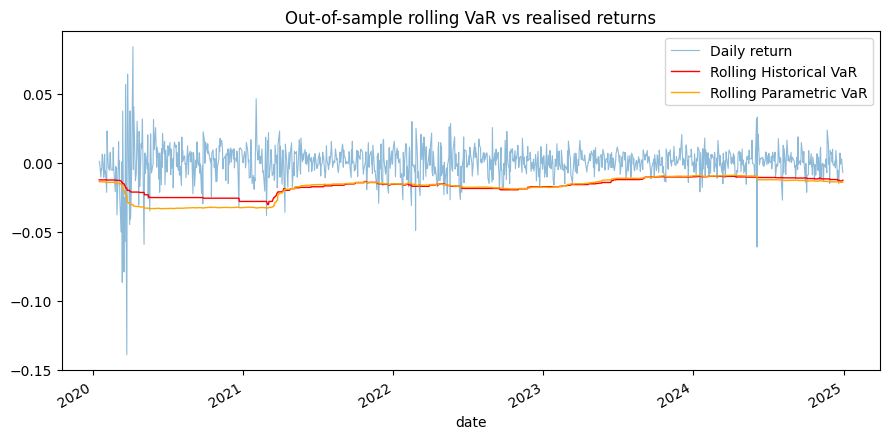

In [17]:
fig, ax = plt.subplots()
bt_historical["actual_return"].plot(ax=ax, alpha=0.5, lw=0.8, label="Daily return")
(-bt_historical["var_estimate"]).plot(ax=ax, color="red", lw=1, label="Rolling Historical VaR")
(-bt_parametric["var_estimate"]).plot(ax=ax, color="orange", lw=1, label="Rolling Parametric VaR")
ax.set_title("Out-of-sample rolling VaR vs realised returns")
ax.legend()
plt.tight_layout()
plt.show()


### Observations

* The plot demonstrates that both Historical and Normal Parametric VaR are **time-varying risk estimates**, not fixed thresholds. Each day's VaR is recalculated using only the preceding 250 trading days, allowing the estimate to respond to changes in the recent volatility environment.
* The most pronounced widening of the VaR bands occurs around the 2020 market shock, when realised returns become exceptionally volatile. As the turbulent observations enter the rolling estimation window, the estimated downside thresholds become substantially more conservative.
* As market conditions become calmer, the VaR estimates gradually move back toward zero. This visually demonstrates the state-dependent nature of market risk:

[
\boxed{\text{Higher recent uncertainty} \rightarrow \text{larger downside-risk estimate}}
]

* The Historical and Normal Parametric VaR lines are similar in overall direction but differ in magnitude because they use different representations of the return distribution. Historical VaR uses the empirical tail of the recent data, whereas Normal Parametric VaR imposes a Normal distribution using the recent mean and standard deviation.
* The graph provides an intuitive visual explanation of the VaR exceptions counted in the Kupiec backtest: whenever a realised negative return falls below the corresponding rolling VaR threshold, a violation occurs.
* The 2020 period illustrates why a fixed VaR estimate would be inadequate for a changing market environment. A single risk number estimated during a calm period would not reflect the much larger uncertainty observed during a turbulent period.
* Importantly, the graph does **not** establish that the Normal model is invalid simply because Section 2 rejected Normality. In the actual out-of-sample results, Historical VaR produced 66 violations and Normal Parametric VaR produced 59, while both models passed the Kupiec unconditional-coverage test.
* Therefore, the visual evidence and the formal backtest complement one another: the graph shows how the models adapt through time, while Kupiec tests whether their overall violation frequencies are statistically consistent with the intended 5% rate.
* This also reinforces an important distinction within the framework:

[
\boxed{\text{Dynamic risk estimation} \neq \text{stress-event detection}}
]

Rolling VaR estimates the size of a plausible downside threshold using recent history, whereas the earlier fast stress flag simply identifies exceptionally negative individual returns.

### Conclusion

The rolling VaR plot shows that both Historical and Normal Parametric VaR respond dynamically to changing market conditions, becoming more conservative during turbulent periods and narrowing during calmer periods. This confirms the practical advantage of the walk-forward design: the model does not assume that the market has one permanent level of risk.

The key conclusion is:

[
\boxed{\text{Market risk is time-varying, so a useful VaR model must adapt to changing conditions}}
]

At the same time, the graph must be interpreted together with the formal backtest. In this sample, neither Historical nor Normal Parametric VaR is rejected by the Kupiec test at the 95% level. Thus, the correct conclusion is not that one model is visually "right" and the other is "wrong", but that **different distributional assumptions produce different dynamic risk thresholds, and their adequacy must ultimately be judged by out-of-sample validation**.


## 7b. Does the fat-tail effect show up at a stricter quantile (99%)?

Both models passed the Kupiec test at 95% (Section 7) — neither was rejected as mis-calibrated. That's not
surprising: 95% is a moderate quantile, and Section 6 showed the ordering between Historical and Parametric
VaR isn't determined by fat tails alone at that level. The 99% quantile is a stricter test — it sits further
into the tail, which is exactly where Student-t's low degrees-of-freedom fit (Section 2) said the normal
distribution understates real risk. Re-running the same walk-forward backtest at 99% checks whether the
Parametric-Normal model's calibration breaks down where theory predicts it should, even though it held up
fine at 95%.

In [18]:
ALPHA_99 = 0.01  # 99% VaR

hvar_99 = ru.historical_var(market_returns, ALPHA_99)
pvar_99 = ru.parametric_var(market_returns, ALPHA_99)

print(f"99% Historical VaR  : {hvar_99:.4%} (daily)")
print(f"99% Parametric VaR  : {pvar_99:.4%} (daily)")
print(f"Difference          : {(hvar_99 - pvar_99):.4%}  "
      f"{'(historical is more conservative)' if hvar_99 > pvar_99 else '(parametric is more conservative)'}")
print()
print(f"For comparison, at 95% (Section 6): Historical {hvar:.4%} vs Parametric {pvar:.4%}")

99% Historical VaR  : 3.1314% (daily)
99% Parametric VaR  : 2.6612% (daily)
Difference          : 0.4703%  (historical is more conservative)

For comparison, at 95% (Section 6): Historical 1.5477% vs Parametric 1.8666%


### Observations

* The 99% VaR analysis provides a stricter examination of the left tail because it focuses on approximately the worst 1% of daily returns rather than the worst 5% used for 95% VaR.
* At 95%, the Normal-parametric VaR was more conservative:

[
VaR_{Historical}=1.5477%
]

[
VaR_{Normal}=1.8666%
]

However, at 99%, the ordering reverses:

[
VaR_{Historical}=3.1314%
]

[
VaR_{Normal}=2.6612%
]

Thus, the empirical Historical VaR exceeds the Normal-parametric estimate by (0.4703%).

* The reversal is important because Section 2 established strong evidence of heavy-tailed, non-Normal returns, including excess kurtosis of (21.88), a Jarque-Bera p-value below (10^{-300}), and a fitted Student-t distribution with approximately 3.15 degrees of freedom.
* At the moderate 95% quantile, the heavy-tail structure does not necessarily force the empirical quantile to exceed the Normal quantile. At the much more extreme 99% quantile, however, the far-tail behaviour becomes more influential, and the empirical distribution produces a substantially larger downside threshold.
* Therefore, the effect of distributional misspecification is **confidence-level dependent**. The same Normal assumption that produced a more conservative estimate at 95% produces a less conservative estimate at 99%.
* For the illustrative ₹4 crore exposure, the 99% Historical VaR corresponds to approximately ₹12.53 lakh of one-day downside risk, compared with approximately ₹10.64 lakh under Normal Parametric VaR. The Normal specification therefore understates the empirical 99% loss threshold by roughly ₹1.89 lakh in this illustration.
* This demonstrates an important model-risk principle: a model may appear adequately conservative at a moderate confidence level while becoming materially less conservative when the analysis moves deeper into the tail.
* The result also shows why the statement **“fat tails always make Normal VaR underestimate risk”** is too simplistic. The correct conclusion must consider the specific confidence level and the actual shape of the empirical distribution.

### Conclusion

The 99% analysis provides empirical evidence that the impact of heavy tails becomes more important in the far-left tail. While Normal Parametric VaR was more conservative than Historical VaR at 95%, the ordering reverses at 99%, with Historical VaR indicating substantially greater downside risk.

The central conclusion is:

[
\boxed{\text{Distributional model risk becomes more consequential as we move deeper into the tail}}
]

and:

[
\boxed{\text{VaR model comparisons must be evaluated at the confidence level relevant to the risk decision}}
]

This result strengthens the framework's central argument: **a risk model cannot be judged solely from its behaviour around moderate quantiles or from overall volatility. Extreme-tail behaviour must be examined explicitly, because that is where an inappropriate distributional assumption can materially understate downside risk.**


In [19]:
bt_historical_99 = ru.rolling_out_of_sample_var(market_returns, window=WINDOW, alpha=ALPHA_99, method="historical")
bt_parametric_99 = ru.rolling_out_of_sample_var(market_returns, window=WINDOW, alpha=ALPHA_99, method="parametric")

print(f"Out-of-sample test period: {len(bt_historical_99)} days "
      f"({bt_historical_99.index.min().date()} to {bt_historical_99.index.max().date()})")
print(f"Historical-VaR violations (99%) : {int(bt_historical_99['violation'].sum())}")
print(f"Parametric-VaR violations (99%) : {int(bt_parametric_99['violation'].sum())}")

print()
for label, bt in [("Historical VaR 99% (out-of-sample)", bt_historical_99),
                   ("Parametric VaR 99% (out-of-sample)", bt_parametric_99)]:
    x = int(bt["violation"].sum())
    T = len(bt)
    kupiec = ru.kupiec_pof_test(x, T, alpha=ALPHA_99)
    print(f"--- {label} ---")
    for k, v in kupiec.items():
        print(f"  {k}: {v}")
    print()

Out-of-sample test period: 1224 days (2020-01-16 to 2024-12-30)
Historical-VaR violations (99%) : 21
Parametric-VaR violations (99%) : 28

--- Historical VaR 99% (out-of-sample) ---
  observed_violations: 21
  expected_violations: 12.24
  observed_rate: 0.01715686274509804
  expected_rate: 0.01
  LR_stat: 5.21563329356502
  p_value: 0.022384692730857775
  reject_model_at_5pct: True

--- Parametric VaR 99% (out-of-sample) ---
  observed_violations: 28
  expected_violations: 12.24
  observed_rate: 0.02287581699346405
  expected_rate: 0.01
  LR_stat: 15.025600095099833
  p_value: 0.00010606261807817584
  reject_model_at_5pct: True



### Observations

* Moving from 95% to 99% makes the VaR validation substantially more demanding because the expected violation probability falls from (5%) to only (1%). Over 1,224 out-of-sample observations, only (12.24) violations are expected under correct 99% calibration.
* Historical VaR produces 21 violations, giving an observed exception rate of (1.72%), compared with the expected (1%). The Kupiec POF statistic is (5.22) with (p=0.0224), so the Historical 99% VaR is rejected at the 5% significance level.
* Normal Parametric VaR produces 28 violations, corresponding to an observed exception rate of (2.29%), more than twice the intended (1%) level. Its Kupiec statistic is (15.03) with (p=0.0001), providing much stronger evidence of miscalibration.
* The comparison therefore shows a clear difference in severity:

[
\boxed{\text{Historical LR}_{POF}=5.22}
]

[
\boxed{\text{Normal LR}_{POF}=15.03}
]

The Normal model's likelihood-ratio statistic is roughly three times larger, indicating substantially greater departure from the intended 1% violation frequency.

* This result provides out-of-sample evidence that the Normal assumption becomes more problematic in the far tail. Section 2 had already shown strong non-Normality through excess kurtosis of (21.88), a Student-t degrees-of-freedom estimate of approximately (3.15), and an extremely significant Jarque-Bera test. At 99%, that heavy-tail behaviour translates into materially higher realised exception frequency under the Normal VaR specification.
* Importantly, **Historical VaR does not pass cleanly either**. Although it performs better than Normal VaR, its 21 violations are still significantly above the expected 12.24. Therefore, avoiding a parametric Normal assumption does not guarantee accurate extreme-tail calibration.
* One explanation is the limited information available in the rolling estimation window. With only 250 observations and a 1% tail probability, the theoretical tail contains only about (2.5) observations per estimation window. This makes empirical 99% VaR inherently sensitive to sampling variability and newly emerging extreme events.
* The ordering between Historical and Normal VaR also reverses between confidence levels:

[
95%:\quad VaR_{Normal}>VaR_{Historical}
]

[
99%:\quad VaR_{Historical}>VaR_{Normal}
]

This shows that **which model is more conservative is confidence-level dependent**, rather than being a permanent property of either methodology.

* The result also demonstrates an important distinction between distributional robustness and empirical tail estimation:

[
\boxed{\text{No parametric assumption} \neq \text{perfect extreme-tail calibration}}
]

* Because Kupiec tests unconditional coverage only, the rejection establishes that the overall frequency of 99% VaR violations is inconsistent with the intended 1% rate. It does not by itself determine whether the violations are clustered in particular market regimes or whether the models fail specifically during stress episodes.

### Conclusion

The 99% walk-forward backtest provides the strongest evidence so far that **extreme-tail VaR is substantially more difficult to calibrate than moderate-tail VaR**. Both models pass Kupiec at 95%, but both are rejected at 99%. The Normal-parametric model is rejected much more strongly, with 28 violations and a Kupiec p-value of approximately (0.0001), compared with 21 violations and (p=0.0224) for Historical VaR.

The central conclusion is:

[
\boxed{\text{The impact of distributional misspecification becomes materially larger in the far tail}}
]

However, the framework also avoids the simplistic conclusion that Historical VaR is automatically reliable:

[
\boxed{\text{Historical VaR outperforms Normal VaR at 99%, but is still statistically miscalibrated}}
]

Thus, the evidence points to two distinct sources of extreme-tail model risk: **parametric misspecification of the tail** under the Normal model and **limited empirical tail information** under a finite rolling Historical window. This is why extreme-risk validation requires both an appropriate distributional perspective and rigorous out-of-sample backtesting.


# 7c. VaR Validation Summary

In [20]:
summary_rows = []

for confidence, alpha_value, backtests in [
    ("95%", alpha, [
        ("Historical", bt_historical),
        ("Parametric-Normal", bt_parametric)
    ]),
    ("99%", ALPHA_99, [
        ("Historical", bt_historical_99),
        ("Parametric-Normal", bt_parametric_99)
    ])
]:
    
    for method, bt in backtests:
        
        violations = int(bt["violation"].sum())
        n_obs = len(bt)
        
        kupiec = ru.kupiec_pof_test(
            violations,
            n_obs,
            alpha=alpha_value
        )
        
        if method == "Historical":
            var_value = ru.historical_var(
                market_returns,
                alpha=alpha_value
            )
        else:
            var_value = ru.parametric_var(
                market_returns,
                alpha=alpha_value
            )
        
        summary_rows.append({
            "Confidence": confidence,
            "Method": method,
            "VaR": var_value,
            "Violations": violations,
            "Expected": kupiec["expected_violations"],
            "Observed Rate": kupiec["observed_rate"],
            "Expected Rate": kupiec["expected_rate"],
            "Kupiec LR": kupiec["LR_stat"],
            "p-value": kupiec["p_value"],
            "Reject @ 5%": kupiec["reject_model_at_5pct"]
        })


# Raw summary table
var_validation_summary = pd.DataFrame(summary_rows)

var_validation_summary

,Confidence,Method,VaR,Violations,Expected,Observed Rate,Expected Rate,Kupiec LR,p-value,Reject @ 5%
0,95%,Historical,0.01548,66,61.20000,0.05392,0.05000,0.38684,0.53397,False
1,95%,Parametric-Normal,0.01867,59,61.20000,0.04820,0.05000,0.08421,0.77167,False
2,99%,Historical,0.03131,21,12.24000,0.01716,0.01000,5.21563,0.02238,True
3,99%,Parametric-Normal,0.02661,28,12.24000,0.02288,0.01000,15.02560,0.00011,True


### Observations

* The consolidated validation results show a clear dependence of VaR model performance on the confidence level. At 95%, both Historical and Normal Parametric VaR produce violation frequencies statistically consistent with the intended 5% rate, with Kupiec p-values of (0.534) and (0.772), respectively.
* At 99%, both models are rejected by the Kupiec POF test. Historical VaR records 21 violations against 12.24 expected ((1.72%) observed versus (1%) expected), while Normal Parametric VaR records 28 violations ((2.29%) observed), resulting in substantially stronger evidence of miscalibration.
* The severity of rejection differs materially:

[
LR_{Historical}=5.22
]

[
LR_{Normal}=15.03
]

Thus, although both models fail the 99% unconditional-coverage requirement, the Normal specification exhibits much greater deviation from the intended tail probability.

* The comparison also reveals a confidence-level-dependent reversal in model conservatism:

[
95%:\quad VaR_{Normal}>VaR_{Historical}
]

[
99%:\quad VaR_{Historical}>VaR_{Normal}
]

Therefore, neither model is uniformly more conservative across all quantiles.

* This reversal is consistent with the earlier distributional evidence. At moderate quantiles, the empirical distribution and the fitted Normal model can produce different but not necessarily systematically ordered thresholds. Deeper in the tail, the heavy-tail behaviour identified through excess kurtosis and the Student-t fit becomes much more consequential.
* Historical VaR also fails at 99%, demonstrating that removing parametric distributional assumptions does not automatically solve extreme-tail calibration. With a 250-day rolling estimation window, a 1% tail corresponds to only approximately 2.5 observations in the theoretical tail per window, creating substantial finite-sample uncertainty.
* The summary therefore reveals two distinct sources of model risk:

[
\boxed{
\text{Normal VaR} \rightarrow \text{distributional misspecification}
}
]

[
\boxed{
\text{Historical VaR} \rightarrow \text{finite-sample tail uncertainty}
}
]

* The results also reinforce the distinction between a VaR estimate and a validated risk model. A numerical VaR threshold may appear reasonable, but its adequacy must be judged by its behaviour on unseen observations and by the frequency with which realised losses breach the threshold.
* The summary combines reference VaR magnitudes with walk-forward backtest results. The full-sample VaR figures therefore provide scale/context, while the violation counts and Kupiec statistics provide the actual out-of-sample validation evidence.

### Conclusion

The consolidated VaR analysis shows that **95% VaR models can appear well calibrated while the same models become materially unreliable when pushed into the extreme 99% tail**. Both Historical and Normal Parametric VaR pass Kupiec at 95%, but both are rejected at 99%, with the Normal specification exhibiting substantially greater miscalibration.

The central conclusion is:

[
\boxed{\text{VaR model adequacy is confidence-level dependent}}
]

and more specifically:

[
\boxed{\text{Moderate-tail calibration does not guarantee extreme-tail calibration}}
]

The evidence therefore supports a nuanced view rather than declaring one VaR methodology universally superior. Normal VaR is more strongly affected by tail misspecification at 99%, while Historical VaR is relatively better but remains vulnerable to limited empirical information in the extreme tail. The overall framework demonstrates why **distributional analysis, dynamic estimation, out-of-sample backtesting, and statistical validation must be considered together when assessing market-risk models.**


In [21]:
var_validation_display = var_validation_summary.copy()

var_validation_display["VaR"] = (
    var_validation_display["VaR"] * 100
).map(lambda x: f"{x:.4f}%")

var_validation_display["Observed Rate"] = (
    var_validation_display["Observed Rate"] * 100
).map(lambda x: f"{x:.2f}%")

var_validation_display["Expected Rate"] = (
    var_validation_display["Expected Rate"] * 100
).map(lambda x: f"{x:.2f}%")

var_validation_display["Kupiec LR"] = (
    var_validation_display["Kupiec LR"]
    .map(lambda x: f"{x:.4f}")
)

var_validation_display["p-value"] = (
    var_validation_display["p-value"]
    .map(format_pvalue)
)

var_validation_display

,Confidence,Method,VaR,Violations,Expected,Observed Rate,Expected Rate,Kupiec LR,p-value,Reject @ 5%
0,95%,Historical,1.5477%,66,61.20000,5.39%,5.00%,0.3868,0.5340,False
1,95%,Parametric-Normal,1.8666%,59,61.20000,4.82%,5.00%,0.0842,0.7717,False
2,99%,Historical,3.1314%,21,12.24000,1.72%,1.00%,5.2156,0.0224,True
3,99%,Parametric-Normal,2.6612%,28,12.24000,2.29%,1.00%,15.0256,0.0001,True


## 8. Conclusions

### 1. Distribution

NIFTY 50 returns are strongly non-Normal. The Jarque-Bera test rejects the Normality hypothesis overwhelmingly ((JB\approx30{,}022,\ p<10^{-300})), while excess kurtosis of approximately (21.9), compared with (0) for a Normal distribution, provides strong evidence of heavy tails. The fitted Student-t distribution has only about (3.15) degrees of freedom, indicating substantial tail heaviness.

The key implication is:

[
\boxed{\text{Overall volatility alone is insufficient to describe market risk; tail behaviour matters.}}
]

### 2. Low- vs High-Volatility Regimes

The 21-day rolling-volatility analysis shows that market risk varies materially through time. The low- and high-volatility regimes contain 727 observations each because the sample median was used as the relative regime cutoff.

Levene's test strongly rejects equal variance ((p\approx3.3\times10^{-26})), confirming that the two regimes represent genuinely different levels of dispersion. However, neither Welch's t-test ((p=0.926)) nor the primary Mann-Whitney U test ((p=0.121)) provides evidence of a statistically significant difference in return location at the 5% level. The 95% confidence interval for the mean difference,

[
(-0.00126,;0.00115),
]

also contains zero.

Thus, the important finding is:

[
\boxed{\text{High volatility does not necessarily mean lower average return.}}
]

The regime distinction appears primarily through **dispersion rather than return direction**. A high-volatility market is therefore a different risk environment, not necessarily a losing environment.

### 3. Systematic Risk

The market-model regressions show materially different systematic exposures across the four stocks.

TCS has:

[
\beta=0.71,\qquad CI_{95%}=[0.61,0.80]
]

and INFY has:

[
\beta=0.84,\qquad CI_{95%}=[0.75,0.93].
]

Both confidence intervals lie entirely below (1), providing evidence that these stocks have lower systematic market sensitivity than NIFTY 50.

RELIANCE has:

[
\beta=1.09,\qquad CI_{95%}=[1.00,1.19],
]

while HDFCBANK has:

[
\beta=1.08,\qquad CI_{95%}=[0.99,1.16].
]

Their point estimates are above (1), but the confidence intervals include values consistent with market Beta (=1); therefore, they cannot be concluded to have statistically higher-than-market Beta at the 5% level.

HDFCBANK has the highest (R^2):

[
R^2=0.577,
]

meaning that approximately 57.7% of its return variation is explained by the single NIFTY market factor. TCS has the lowest:

[
R^2=0.292,
]

so a much larger proportion of its return variation is not explained by this one-factor market model.

The key distinction is:

[
\boxed{\text{Volatility} \neq \text{Beta} \neq R^2}
]

Volatility measures overall dispersion, Beta measures systematic market sensitivity, and (R^2) measures the explanatory power of the market factor.

### 4. Detection Trade-off

The fast single-day extreme-return rule shows a pronounced trade-off between false-alarm control and detection sensitivity.

Moving from the worst 10% to the worst 1% of returns:

[
Recall: 14.6%\rightarrow2.1%
]

while:

[
Specificity:94.4%\rightarrow100%.
]

Correspondingly:

[
Type\ I\ error:5.6%\rightarrow0%
]

while:

[
Type\ II\ error:85.4%\rightarrow97.9%.
]

The central finding is:

[
\boxed{\text{Stricter shock thresholds reduce false alarms but miss more high-volatility observations.}}
]

This also provides empirical support for the earlier distinction:

[
\boxed{\text{Extreme return} \neq \text{high-volatility regime}}
]

A single-day shock rule is therefore a poor proxy for a persistent volatility state. This analysis is explicitly **in-sample and retrospective** and should not be interpreted as evidence that any threshold would function as a live early-warning signal.

### 5. Model Validation at 95%

At the 95% confidence level, neither VaR model is rejected by the out-of-sample Kupiec POF test.

Historical VaR:

[
p=0.534
]

Normal Parametric VaR:

[
p=0.772.
]

Over the 1,224-day out-of-sample period, Historical VaR produces 66 violations versus 61.2 expected, while Normal Parametric VaR produces 59 versus 61.2 expected.

Thus:

[
\boxed{\text{Both models are statistically consistent with the 5% violation rate at 95%.}}
]

This means the models pass the **Kupiec unconditional-coverage test**; it does not prove that either model is universally correct.

### 6. Model Validation at 99%

The picture changes materially at the stricter 99% confidence level.

Historical VaR produces:

[
21\text{ violations}
]

versus:

[
12.24\text{ expected},
]

with:

[
p=0.0224.
]

Normal Parametric VaR produces:

[
28\text{ violations}
]

with:

[
p=0.0001.
]

Both models are therefore rejected by Kupiec at the 5% significance level, but the Normal model exhibits substantially stronger miscalibration:

[
LR_{Historical}=5.22
]

versus:

[
LR_{Normal}=15.03.
]

The normal specification therefore produces a much larger excess of extreme-loss violations in the far tail. This is consistent with the earlier evidence of heavy-tailed, non-Normal returns and shows that the consequences of distributional misspecification become more important at a deeper quantile.

Importantly, Historical VaR is **not** a perfect solution: it also fails the 99% Kupiec test. With only a 250-day rolling estimation window, the 1% tail contains very little empirical information, so finite-sample uncertainty becomes substantial.

The key conclusion is:

[
\boxed{\text{Moderate-tail calibration does not guarantee extreme-tail calibration.}}
]

### Overall Risk-Management Conclusion

The project's central contribution is not simply the calculation of descriptive statistics, Beta, or VaR. It is the **statistical validation of how different market-risk measurements behave under changing distributional and volatility conditions**.

The framework demonstrates that:

[
\boxed{
\text{Return performance}
\neq
\text{Risk characteristics}
}
]

[
\boxed{
\text{Extreme return}
\neq
\text{High-volatility regime}
}
]

[
\boxed{
\text{Volatility}
\neq
\text{Systematic exposure}
}
]

and, most importantly:

[
\boxed{
\text{A VaR estimate}
\neq
\text{a validated risk model}
}
]

A model must be evaluated against unseen outcomes, at the confidence level for which it is intended to be used. In this framework, both 95% VaR models are statistically consistent with their target exception rate, while both become miscalibrated at 99%, with the Normal specification showing substantially greater deterioration. This illustrates why **distributional assumptions, regime behaviour, tail estimation, and out-of-sample validation must be considered together when assessing market risk.**
